# Carteras con evidencia: media vs. Dempster–Shafer
*UPC Quant Society · con Iker Caballero (Univ. de Bristol)*

Tenemos 10 activos y tres modelos que, cada 1 de enero, estiman $p(\text{up})$: la probabilidad de que el activo suba en el año que empieza. Combinamos **las mismas predicciones** de dos formas, **media** o **Dempster–Shafer**, y comparamos las carteras resultantes.

1. Datos y target
2. Predicciones de ML
3. Backtest walk-forward (train / validation / test)
4. Benchmark (media)
5. Dempster–Shafer
6. Reliability $r$
7. Cartera DS (threshold + cash)
8. Comparación

Basado en la sección 2 de Huang, Newton, Platanakis & Ye (2026), [DOI 10.1080/14697688.2026.2633448](https://doi.org/10.1080/14697688.2026.2633448). Las masas y la cartera top‑5 son una adaptación para clase.

---
## 1. Datos y target
**¿Qué sabemos el día que decidimos y qué queremos predecir?**

Usamos SPY y los 9 ETF sectoriales SPDR originales (XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY), con *adjusted close* de Yahoo Finance, que incluye dividendos y *splits*. Son los ETF con la historia común más larga, y al ser activos parecidos podemos entrenar un solo modelo con las filas de los 10.
*Limitaciones:* *survivorship bias* (los elegimos hoy sabiendo que han sobrevivido); los 10 son renta variable de EE. UU. muy correlacionada; y su composición ha cambiado (reclasificación GICS de 2018).

In [14]:
# Setup: descarga de precios. Ejecuta esta celda y sigue.
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
pd.set_option("display.float_format", "{:.4f}".format)

TICKERS = ["SPY", "XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
PRIMER_AÑO, ULTIMO_AÑO = 1998, 2025   # 2026 aún no ha terminado


def descargar_precios(tickers, intentos=3):
    # Yahoo a veces devuelve vacío un ticker ("possibly delisted"): reintentamos los que falten.
    precios, pendientes = pd.DataFrame(), list(tickers)
    for _ in range(intentos):
        datos = yf.download(pendientes, start=f"{PRIMER_AÑO}-01-01", end=f"{ULTIMO_AÑO + 1}-01-01",
                            auto_adjust=True, progress=False)
        precios = pd.concat([precios, datos["Close"].dropna(axis=1, how="all")], axis=1).sort_index()
        pendientes = [t for t in tickers if t not in precios.columns]
        if not pendientes:
            return precios[tickers]
        time.sleep(3)
    raise RuntimeError(f"Sin datos para {pendientes}. Reintenta en unos minutos.")


def ultimo_dia_habil(año):
    return precios.loc[str(año)].index[-1]


precios = descargar_precios(TICKERS)

# Un año cuenta si los 10 activos tienen precio en todas sus sesiones y en el último cierre del año anterior.
años_completos = [a for a in range(PRIMER_AÑO + 1, ULTIMO_AÑO + 1)
                  if precios.loc[ultimo_dia_habil(a - 1)].notna().all()
                  and precios.loc[str(a)].notna().all().all()]
print(f"Años completos comunes: {años_completos[0]}–{años_completos[-1]} ({len(años_completos)} años)")

Años completos comunes: 1999–2025 (27 años)


### La convención que no podemos romper

El modelo ve hasta T-1 y por lo tanto nuestra decisión y entry price es en el cierre de T-1.

De la misma forma, el último cierre es en T y ahí es nuestro exit price también.

$$R_T = \frac{P(\text{cierre } T)}{P(\text{cierre } T-1)} - 1, \qquad \text{label} = \mathbb{1}[R_T > 0]$$

Las tres features usan **solo** precios hasta el último cierre de $T-1$:
- `rent_12m`: rentabilidad del año $T-1$;
- `rent_3m`: rentabilidad del último trimestre de $T-1$;
- `vol_12m`: volatilidad diaria de $T-1$, anualizada.

*Simplificación:* suponemos que compramos al mismo cierre con el que calculamos las features.

Identificación                       \
          activo año_T fecha_decision   
0            XLF  2008     2007-12-31   

  Features (lo que ve el modelo, cierre de T−1)                  \
                                       rent_12m rent_3m vol_12m   
0                                       -0.1918 -0.1494  0.2407   

  Target (solo se sabe después, durante T)                                 \
                            periodo_target entry_price exit_price  rent_T   
0                  2007-12-31 → 2008-12-31     16.4175     7.4039 -0.5490   

         
  label  
0     0

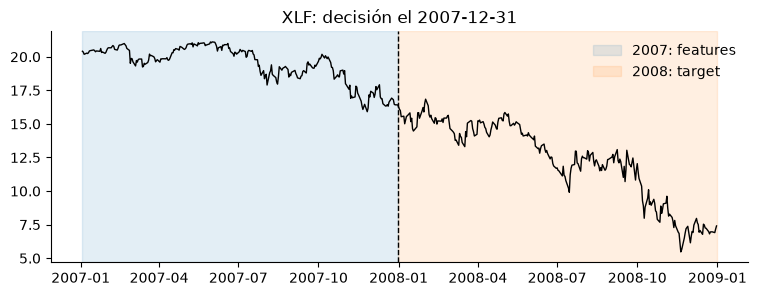

In [16]:
def construir_fila(activo, año):
    p = precios[activo]
    decision = ultimo_dia_habil(año - 1)                  # última observación usada = entry
    inicio = ultimo_dia_habil(año - 2)
    trimestre = p.loc[:f"{año - 1}-09-30"].index[-1]
    salida = ultimo_dia_habil(año)

    log_diarios = np.log(p.loc[inicio:decision]).diff().dropna()
    rent_T = p[salida] / p[decision] - 1
    return {
        "activo": activo, "año_T": año, "fecha_decision": decision.date(),
        # features: lo que ve el modelo
        "rent_12m": p[decision] / p[inicio] - 1,
        "rent_3m": p[decision] / p[trimestre] - 1,
        "vol_12m": log_diarios.std() * np.sqrt(252),
        # target: lo que solo sabremos después
        "periodo_target": f"{decision.date()} → {salida.date()}",
        "entry_price": p[decision], "exit_price": p[salida],
        "rent_T": rent_T, "label": int(rent_T > 0),
    }


def mostrar_ejemplo(activo, año):
    fila = construir_fila(activo, año)
    grupos = {
        "Identificación": ["activo", "año_T", "fecha_decision"],
        "Features (lo que ve el modelo, cierre de T−1)": ["rent_12m", "rent_3m", "vol_12m"],
        "Target (solo se sabe después, durante T)": ["periodo_target", "entry_price", "exit_price", "rent_T", "label"],
    }
    columnas = pd.MultiIndex.from_tuples([(g, c) for g, cols in grupos.items() for c in cols])
    display(pd.DataFrame([[fila[c] for _, c in columnas]], columns=columnas))

    p = precios[activo].loc[str(año - 1):str(año)]
    decision = ultimo_dia_habil(año - 1)
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(p, color="black", lw=1)
    ax.axvspan(p.index[0], decision, color="tab:blue", alpha=0.12, label=f"{año - 1}: features")
    ax.axvspan(decision, p.index[-1], color="tab:orange", alpha=0.12, label=f"{año}: target")
    ax.axvline(decision, color="black", ls="--", lw=1)
    ax.set_title(f"{activo}: decisión el {decision.date()}")
    ax.legend(loc="best", frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()


mostrar_ejemplo("XLF", 2008)

**Lectura del ejemplo:** el 31‑dic‑2007 sabíamos que XLF venía de un 2007 negativo y volátil. En 2008 perdió más de la mitad de su valor, así que su label es 0. Los *adjusted prices* no coinciden con los que se veían en pantalla en 2007: sirven para medir rentabilidades.

> Antes de ejecutar, apuesta: ¿qué label tendrá **XLF en 2009**? ¿Y **XLK en 2001**? ¿Te ayudan las features? Después ejecuta `mostrar_ejemplo(...)` para comprobarlo.

Identificación                       ...                        
          activo año_T fecha_decision  ... exit_price rent_T label
0            XLF  2009     2008-12-31  ...     8.7044 0.1757     1

[1 rows x 11 columns]

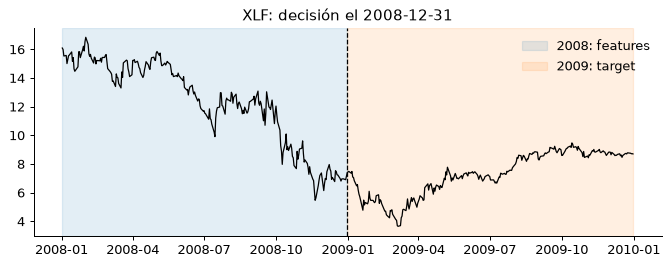

In [3]:
mostrar_ejemplo("XLF", 2009)

### Leakage (look-ahead bias)

Hay **leakage** cuando una feature contiene información que el día de la decisión todavía no existía. El resultado parece buenísimo, pero es imposible de conseguir en la realidad.

Aún no hay modelo. Usamos una regla mínima: **cada año compramos los 5 activos con mayor `rent_3m`**. Un compañero propone otra forma de calcular `rent_3m`. Mira qué fechas usa cada versión en el caso de XLF 2008, con decisión el 31‑dic‑2007:

In [4]:
def rent_3m_compañero(activo, año):
    p = precios[activo]
    return p.loc[:f"{año}-03-31"].iloc[-1] / p.loc[:f"{año - 1}-12-31"].iloc[-1] - 1


decision = ultimo_dia_habil(2007)
pd.DataFrame({
    "desde": [precios.loc[:"2007-09-30"].index[-1].date(), decision.date()],
    "hasta": [decision.date(), precios.loc[:"2008-03-31"].index[-1].date()],
    "valor": [construir_fila("XLF", 2008)["rent_3m"], rent_3m_compañero("XLF", 2008)],
}, index=["rent_3m correcta", "rent_3m del compañero"])

,desde,hasta,valor
rent_3m correcta,2007-09-28,2007-12-31,-0.1494
rent_3m del compañero,2007-12-31,2008-03-31,-0.1334


> ¿Qué versión usa precios que el 31‑dic‑2007 aún no existían? Antes de ejecutar la siguiente celda, apuesta: ¿qué cartera top‑5 ganará más, y por cuánto?

In [5]:
filas_ej = []
for año in años_completos[1:]:
    for activo in TICKERS:
        fila = construir_fila(activo, año)
        fila["rent_3m_compañero"] = rent_3m_compañero(activo, año)
        filas_ej.append(fila)
ej = pd.DataFrame(filas_ej)

carteras = {
    "Top-5 por rent_3m correcta": ej.groupby("año_T").apply(lambda g: g.nlargest(5, "rent_3m")["rent_T"].mean()),
    "Top-5 por rent_3m del compañero (leakage)": ej.groupby("año_T").apply(lambda g: g.nlargest(5, "rent_3m_compañero")["rent_T"].mean()),
    "Equal weight (10 × 10 %)": ej.groupby("año_T")["rent_T"].mean(),
}
pd.DataFrame({
    "rent. anual media": {k: v.mean() for k, v in carteras.items()},
    "1 € se convierte en": {k: (1 + v).prod() for k, v in carteras.items()},
})

,rent. anual media,1 € se convierte en
Top-5 por rent_3m correcta,0.0908,6.8386
Top-5 por rent_3m del compañero (leakage),0.1369,21.4092
Equal weight (10 × 10 %),0.0977,8.4694


La versión con leakage ya conoce el primer trimestre del año que intenta predecir. Es como apostar a un partido viendo el marcador del descanso. En el backtest del bloque 3 este error aparecerá de formas más sutiles: entrenar con años cuyo resultado aún no se conocía, o ajustar el scaler, la reliability o el threshold mirando el año de test.

### Todas las filas

26 años objetivo (2000–2025) × 10 activos = 260 filas
Filas con label 1: 74%


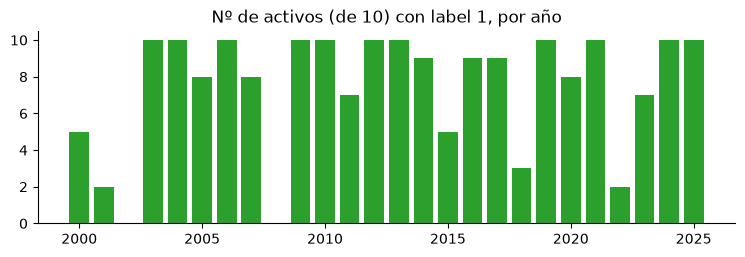

In [17]:
años_objetivo = años_completos[1:]          # el primero solo sirve para calcular features
tabla = pd.DataFrame([construir_fila(a, t) for t in años_objetivo for a in TICKERS])
FEATURES = ["rent_12m", "rent_3m", "vol_12m"]

print(f"{len(años_objetivo)} años objetivo ({años_objetivo[0]}–{años_objetivo[-1]}) × 10 activos = {len(tabla)} filas")
print(f"Filas con label 1: {tabla['label'].mean():.0%}")

positivos = tabla.groupby("año_T")["label"].sum()
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.bar(positivos.index, positivos.values, color="tab:green")
ax.set_title("Nº de activos (de 10) con label 1, por año")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

> Tenemos 260 filas. Mirando el gráfico, ¿cuántas observaciones *independientes* creeis que tenemos en realidad? ¿Qué implica para un modelo que prediga siempre «up»?